<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Sign_Language_Mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#!pip install ultralytics -q
import os
import pandas as pd
import numpy as np
import cv2
from google.colab import files

In [ ]:
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d datamunge/sign-language-mnist
!unzip sign-language-mnist.zip

Saving kaggle.json to kaggle (2).json
Dataset URL: https://www.kaggle.com/datasets/datamunge/sign-language-mnist
License(s): CC0-1.0
sign-language-mnist.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  sign-language-mnist.zip
replace amer_sign2.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace amer_sign3.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace american_sign_language.PNG? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace sign_mnist_test.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [ ]:
def create_yolo_data(csv_path, output_folder):
    if not os.path.exists(output_folder):
        os.makedirs(os.path.join(output_folder, "images"))
        os.makedirs(os.path.join(output_folder, "labels"))

    df = pd.read_csv(csv_path)
    labels = df.iloc[:, 0].values
    pixels = df.iloc[:, 1:].values

    for i, (label, pixel_row) in enumerate(zip(labels, pixels)):
        img = pixel_row.reshape(28, 28).astype(np.uint8)
        img_name = f"img_{i}.jpg"
        cv2.imwrite(os.path.join(output_folder, "images", img_name), img)
        with open(os.path.join(output_folder, "labels", f"img_{i}.txt"), "w") as f:
            f.write(f"{label} 0.5 0.5 1.0 1.0")

create_yolo_data('sign_mnist_train.csv', 'datasets/train')
create_yolo_data('sign_mnist_test.csv', 'datasets/val')

In [ ]:
yaml_content = f"""
train: /content/datasets/train/images
val: /content/datasets/val/images

nc: 24
names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
"""

with open("data.yaml", "w") as f:
    f.write(yaml_content)

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11m.pt')

results = model.train(
    data='data.yaml',
    epochs=25,
    imgsz=64,
    batch=32,
    name='sign_language_model'
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, int8=False,

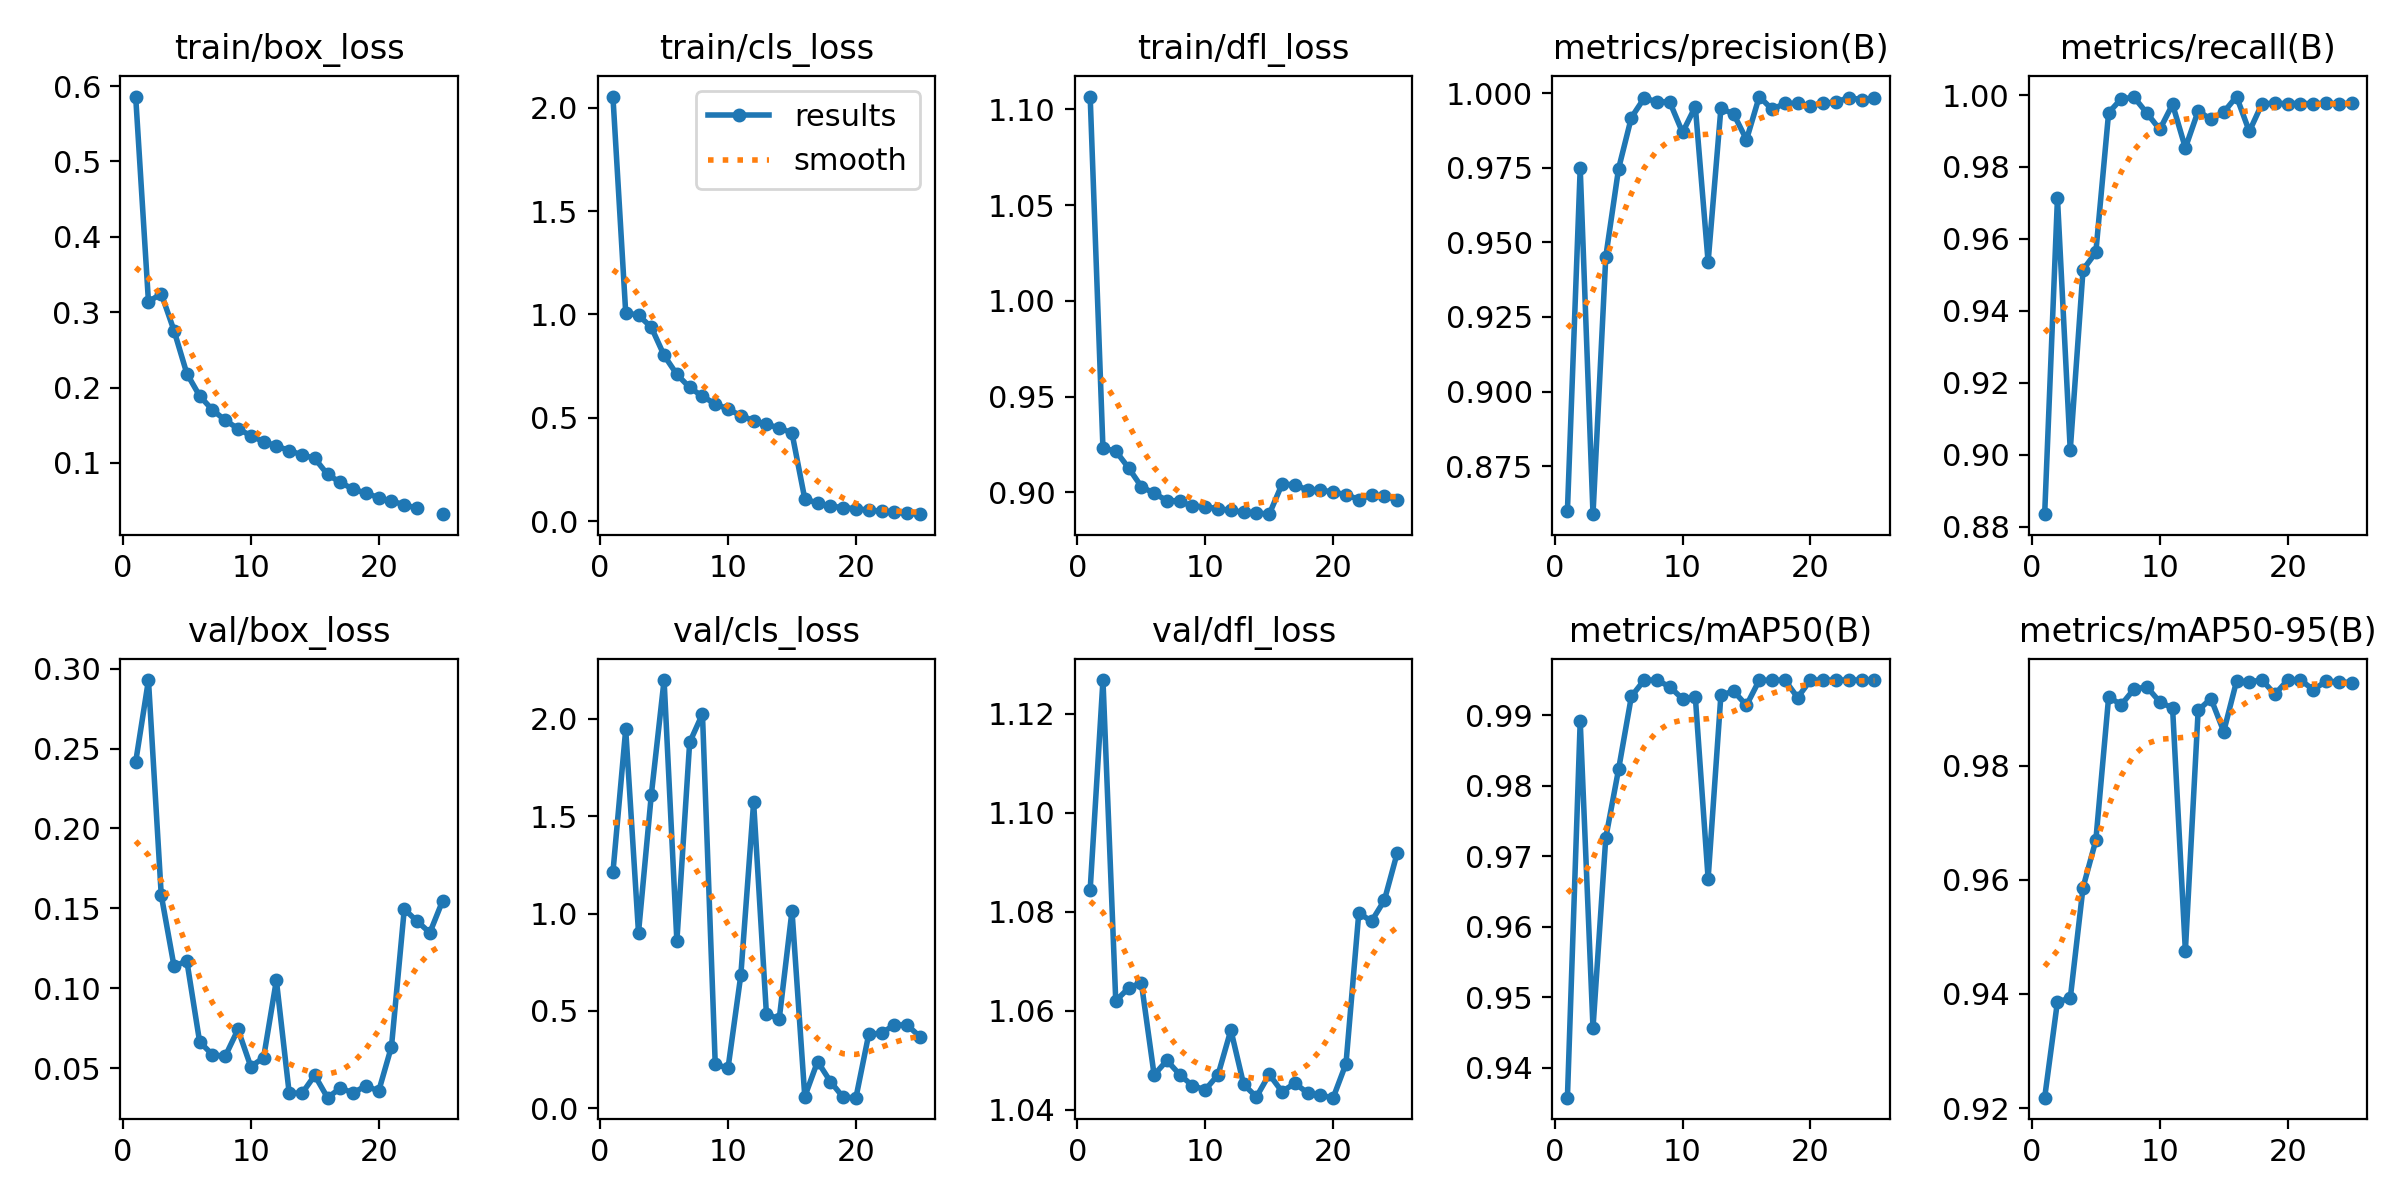

In [ ]:
from IPython.display import Image, display

display(Image(filename='/content/runs/detect/sign_language_model/results.png'))


image 1/1 /content/WhatsApp Image 2026-05-15 at 15.39.00.jpeg: 64x64 1 A, 1 F, 10.6ms
Speed: 0.4ms preprocess, 10.6ms inference, 1.2ms postprocess per image at shape (1, 3, 64, 64)
Results saved to /content/runs/detect/predict-3


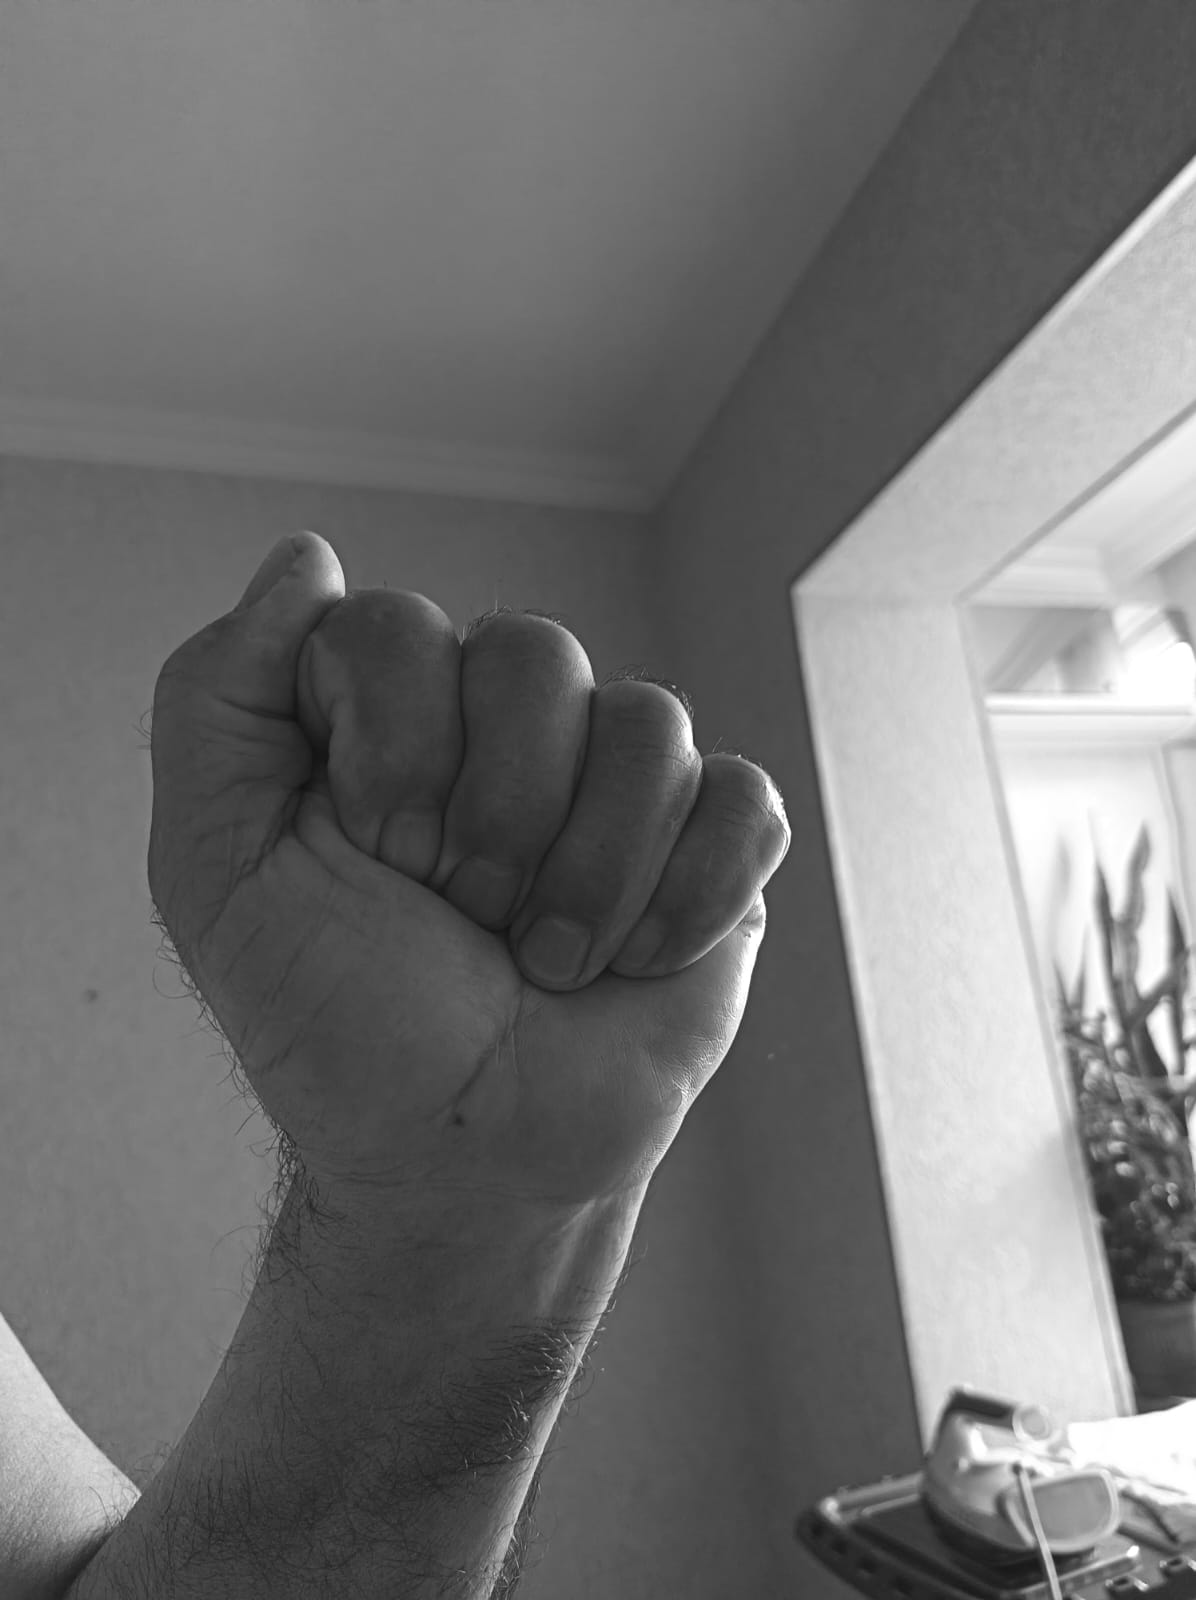

In [ ]:
best_model = YOLO('/content/runs/detect/sign_language_model/weights/best.pt')

result = best_model.predict(source='/content/WhatsApp Image 2026-05-15 at 15.39.00.jpeg', save=True)
predicted_img = '/content/WhatsApp Image 2026-05-15 at 15.39.00.jpeg'
if os.path.exists(predicted_img):
    display(Image(filename=predicted_img))

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import torchvision.models as models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"İstifadə olunan cihaz: {device}")

İstifadə olunan cihaz: cuda


In [ ]:
class SignLanguageDataset(Dataset):
    def __init__(self, csv_file, transform=None):
        data = pd.read_csv(csv_file)
        self.labels = data.iloc[:, 0].values
        self.images = data.iloc[:, 1:].values.astype(np.uint8).reshape(-1, 28, 28)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]
        image = np.stack((image,)*3, axis=-1)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

transform_train = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


train_dataset = SignLanguageDataset('/content/sign_mnist_train.csv', transform=transform_train)
test_dataset = SignLanguageDataset('/content/sign_mnist_test.csv', transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
model = models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 25)

model = model.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [ ]:
epochs = 15

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {running_loss/len(train_loader):.4f} | Train Acc: {100.*correct/total:.2f}%")

Epoch [1/15] | Loss: 1.1742 | Train Acc: 69.09%
Epoch [2/15] | Loss: 0.5402 | Train Acc: 85.54%
Epoch [3/15] | Loss: 0.4176 | Train Acc: 88.63%
Epoch [4/15] | Loss: 0.3518 | Train Acc: 90.18%
Epoch [5/15] | Loss: 0.3158 | Train Acc: 91.13%
Epoch [6/15] | Loss: 0.2872 | Train Acc: 91.64%
Epoch [7/15] | Loss: 0.2704 | Train Acc: 92.01%
Epoch [8/15] | Loss: 0.2582 | Train Acc: 92.25%
Epoch [9/15] | Loss: 0.2494 | Train Acc: 92.41%
Epoch [10/15] | Loss: 0.2360 | Train Acc: 92.77%
Epoch [11/15] | Loss: 0.2293 | Train Acc: 92.91%
Epoch [12/15] | Loss: 0.2273 | Train Acc: 92.93%
Epoch [13/15] | Loss: 0.2136 | Train Acc: 93.43%
Epoch [14/15] | Loss: 0.2080 | Train Acc: 93.44%
Epoch [15/15] | Loss: 0.2030 | Train Acc: 93.60%


In [ ]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

print(f"\n[NƏTİCƏ] Modelin Test Dəqiqliyi (Test Accuracy): {100.*test_correct/test_total:.2f}%")


[NƏTİCƏ] Modelin Test Dəqiqliyi (Test Accuracy): 78.03%


In [ ]:
torch.save(model.state_dict(), 'resnet18_sign_language.pth')

from google.colab import files
files.download('resnet18_sign_language.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import cv2
from PIL import Image
import torch
import matplotlib.pyplot as plt

classes = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M',
           'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
class_mapping = {i: classes[i] if i < 9 else classes[i-1] for i in range(25) if i != 9}

print("Zəhmət olmasa təxmin etmək istədiyiniz əl jesti şəklini yükləyin:")
uploaded = files.upload()

for filename in uploaded.keys():
    # Şəkli oxuyuruq
    img_bgr = cv2.imread(filename)

    # Dataset boz (grayscale) şəkillərdən ibarət olduğu üçün real şəkli əvvəlcə boza çeviririk,
    # kontrastını düzəldirik və ResNet 3 kanal gözlədiyi üçün yenidən 3 kanallı edirik.
    # Bu proses kameradakı dəqiqliyi artırmaq üçün də vacibdir.
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)
    img_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

    # Model üçün təyin etdiyimiz test transformunu tətbiq edirik
    # (transform_test obyektinin yuxarıdakı xanalarda icra olunduğundan əmin olun)
    input_tensor = transform_test(img_rgb).unsqueeze(0).to(device)

    # 3. Model vasitəsilə Təxmin (Inference)
    model.eval()
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted = torch.max(probabilities, 1)
        pred_idx = predicted.item()

    # İndeksi hərfə çeviririk
    predicted_letter = class_mapping.get(pred_idx, "Tapılmadı")
    confidence_percent = confidence.item() * 100

    # 4. Nəticəni vizuallaşdırma
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"Təxmin: {predicted_letter} ({confidence_percent:.2f}%)", fontsize=16, color='green')
    plt.axis('off')
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

full_train_df = pd.read_csv('sign_mnist_train.csv')

train_df, val_df = train_test_split(full_train_df, test_size=0.2, random_state=42, stratify=full_train_df.iloc[:, 0])

test_df = pd.read_csv('sign_mnist_test.csv')

print(f"Train sətir sayı: {len(train_df)}")
print(f"Validation sətir sayı: {len(val_df)}")
print(f"Test sətir sayı: {len(test_df)}")

Train sətir sayı: 21964
Validation sətir sayı: 5491
Test sətir sayı: 7172


In [ ]:
class SignLanguageDatasetFromDF(Dataset):
    def __init__(self, dataframe, transform=None):
        self.labels = dataframe.iloc[:, 0].values
        self.images = dataframe.iloc[:, 1:].values.astype(np.uint8).reshape(-1, 28, 28)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]
        image = np.stack((image,)*3, axis=-1)
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)
transform_train = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = SignLanguageDatasetFromDF(train_df, transform=transform_train)
val_dataset = SignLanguageDatasetFromDF(val_df, transform=transform_test)
test_dataset = SignLanguageDatasetFromDF(test_df, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
epochs = 15

for epoch in range(epochs):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"  Train -> Loss: {train_loss/len(train_loader):.4f} | Acc: {100.*train_correct/train_total:.2f}%")
    print(f"  Val   -> Loss: {val_loss/len(val_loader):.4f} | Acc: {100.*val_correct/val_total:.2f}%")
    print("-" * 50)

Epoch [1/15]
  Train -> Loss: 1.2864 | Acc: 66.49%
  Val   -> Loss: 0.6812 | Acc: 84.19%
--------------------------------------------------
Epoch [2/15]
  Train -> Loss: 0.5962 | Acc: 84.34%
  Val   -> Loss: 0.4922 | Acc: 87.51%
--------------------------------------------------
Epoch [3/15]
  Train -> Loss: 0.4557 | Acc: 87.83%
  Val   -> Loss: 0.3839 | Acc: 90.42%
--------------------------------------------------
Epoch [4/15]
  Train -> Loss: 0.3929 | Acc: 89.25%
  Val   -> Loss: 0.3285 | Acc: 91.97%
--------------------------------------------------
Epoch [5/15]
  Train -> Loss: 0.3474 | Acc: 90.24%
  Val   -> Loss: 0.2986 | Acc: 92.19%
--------------------------------------------------
Epoch [6/15]
  Train -> Loss: 0.3164 | Acc: 90.85%
  Val   -> Loss: 0.2496 | Acc: 93.55%
--------------------------------------------------
Epoch [7/15]
  Train -> Loss: 0.2917 | Acc: 91.72%
  Val   -> Loss: 0.2350 | Acc: 93.75%
--------------------------------------------------
Epoch [8/15]
  Train

In [ ]:
torch.save(model.state_dict(), 'resnet18_sign_language_w_val.pth')

from google.colab import files
files.download('resnet18_sign_language_w_val.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>